# Análisis de las 10.000 Empresas más Grandes de Colombia

## Fuente de los datos

**Conjunto de datos:** 10.000 Empresas más Grandes del País

**Fuente:** Portal de Datos Abiertos de Colombia  
**Entidad publicadora:** Superintendencia de Sociedades  
**Sector:** Comercio, Industria y Turismo

**Enlace al conjunto de datos:**  
https://www.datos.gov.co/Comercio-Industria-y-Turismo/10-000-Empresas-mas-Grandes-del-Pa-s/6cat-2gcs/about_data

## Condiciones de uso

Los datos provienen del Portal Nacional de Datos Abiertos de Colombia (datos.gov.co) y pueden ser utilizados, reutilizados y transformados para realizar análisis e investigación, respetando las condiciones de uso del portal.

Para el uso de los datos se debe citar la fuente como:

> Fuente: Portal de Datos Abiertos www.datos.gov.co

También se debe conservar la información relacionada con la fecha de actualización y las condiciones de uso aplicables al conjunto de datos.

## Preguntas de investigación

1. ¿Qué macrosector económico concentra mayores ingresos operacionales?
2. ¿Qué región concentra los mayores ingresos operacionales?
3. ¿Qué macrosectores concentran el mayor número de empresas?
4. ¿Las empresas con más activos también tienen más ingresos operacionales y más patrimonio?

## Datos usados (snapshot)
Archivo `10_000_Empresas_mas_Grandes_del_País_20260927.csv`, descargado el 27/09/2026 y guardado en este repositorio. Contiene 50.000 filas: las 10.000 empresas más grandes de cada año, de 2021 a 2025, con 14 columnas (identificación, ubicación, sector y cifras financieras). Todo el análisis se hace sobre este archivo local.

### Carga del dataset
Cargué el archivo CSV local para que el análisis siempre use los mismos datos, aunque el portal cambie después. Importé las librerías que voy a usar para tablas (pandas) y gráficos (matplotlib y seaborn). Defino también `UNIDAD`, el texto de la unidad monetaria que se usa en los ejes de todos los gráficos: si se corrige, se cambia solo aquí.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Unidad de las cifras de dinero. Confirmar en la descripción de columnas del portal.
UNIDAD = "billones COP"

df = pd.read_csv("10_000_Empresas_mas_Grandes_del_País_20260927.csv")
print(df.shape)
df.head()

(50000, 14)


,NIT,RAZÓN SOCIAL,SUPERVISOR,REGIÓN,DEPARTAMENTO DOMICILIO,CIUDAD DOMICILIO,CIIU,MACROSECTOR,INGRESOS OPERACIONALES,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO,Año de Corte
0,"899,999,068",ECOPETROL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",610,MINERO,$ 100.59,$ 9.03,$ 198.11,$ 114.35,$ 83.76,"2,025"
1,"830,095,213",ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.","4,661",COMERCIO,$ 26.40,$ 0.63,$ 8.11,$ 4.70,$ 3.41,"2,025"
2,"900,112,515",REFINERIA DE CARTAGENA S.A.,SUPERSERVICIOS,REGIÓN CARIBE,BOLIVAR,CARTAGENA,"1,921",MANUFACTURA,$ 22.40,-$ 0.82,$ 34.95,$ 11.57,$ 23.38,"2,025"
3,"900,276,962",D1 S.A.S.,SUPERSOCIEDADES,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.","4,711",COMERCIO,$ 21.61,$ 0.42,$ 6.94,$ 6.72,$ 0.21,"2,025"
4,"890,904,996",EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,ANTIOQUIA,ANTIOQUIA,MEDELLÍN,"3,513",SERVICIOS,$ 20.29,$ 4.88,$ 71.08,$ 36.11,$ 34.97,"2,025"


### Resumen antes de la limpieza
Reviso los tipos de dato y los vacíos tal como llegan los datos. Las columnas de dinero aparecen como texto (`object`) en vez de número, y el año también. Eso es lo que hay que arreglar en la limpieza.

In [2]:
df.info()
print()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   NIT                     50000 non-null  str  
 1   RAZÓN SOCIAL            50000 non-null  str  
 2   SUPERVISOR              50000 non-null  str  
 3   REGIÓN                  50000 non-null  str  
 4   DEPARTAMENTO DOMICILIO  50000 non-null  str  
 5   CIUDAD DOMICILIO        50000 non-null  str  
 6   CIIU                    50000 non-null  str  
 7   MACROSECTOR             50000 non-null  str  
 8   INGRESOS OPERACIONALES  50000 non-null  str  
 9   GANANCIA (PÉRDIDA)      50000 non-null  str  
 10  TOTAL ACTIVOS           50000 non-null  str  
 11  TOTAL PASIVOS           50000 non-null  str  
 12  TOTAL PATRIMONIO        50000 non-null  str  
 13  Año de Corte            50000 non-null  str  
dtypes: str(14)
memory usage: 5.3 MB

NIT                       0
RAZÓN SOCIAL        

### Valores faltantes
No hay valores vacíos en ninguna columna (0 en todas). Por eso no eliminé ni rellené nada. Si hubieran aparecido, habría revisado cuántos eran: pocos se podían borrar, y muchos habría que decidirlos columna por columna para no distorsionar los totales.

Ojo con otra cosa: hay empresas con ganancia negativa (pérdidas) y con patrimonio negativo. No son errores de datos, son empresas reales que perdieron dinero, así que las conservo (se cuentan más abajo).

### Limpieza 1: columna de ingresos
Los ingresos venían como texto con el símbolo `$` y espacios (ejemplo: "$ 100.59"). Python no puede sumar ni promediar texto, así que quité el `$` y los espacios y convertí la columna a número decimal. Sin este paso no se podría responder ninguna pregunta sobre ingresos.

In [3]:
df["INGRESOS OPERACIONALES"] = (
    df["INGRESOS OPERACIONALES"]
    .str.replace("$", "", regex=False)
    .str.replace(" ", "", regex=False)
    .astype(float)
)

df["INGRESOS OPERACIONALES"].describe()

count    50000.000000
mean         0.171192
std          1.365192
min          0.010000
25%          0.030000
50%          0.050000
75%          0.100000
max        144.820000
Name: INGRESOS OPERACIONALES, dtype: float64

### Limpieza 2: NIT, año y duplicados
El NIT y el año venían con comas (ejemplo: "899,999,068" y "2,025"). Al NIT le quité las comas pero lo dejé como texto, porque es solo un código que identifica a la empresa y nunca lo voy a sumar. Al año sí lo convertí a número entero. Después revisé que no hubiera la misma empresa repetida en el mismo año, porque eso inflaría los ingresos sin razón.

In [4]:
df["NIT"] = df["NIT"].str.replace(",", "", regex=False)
df["Año de Corte"] = df["Año de Corte"].str.replace(",", "", regex=False).astype(int)

duplicados = df.duplicated(subset=["NIT", "Año de Corte"]).sum()
print(f"Filas duplicadas (mismo NIT y mismo año): {duplicados}")

Filas duplicadas (mismo NIT y mismo año): 0


### Limpieza 3: demás columnas de dinero
Apliqué la misma limpieza a ganancia, activos, pasivos y patrimonio. Las necesito como números para calcular la matriz de correlación y comparar qué tan relacionadas están entre sí.

In [5]:
otras_cols = ["GANANCIA (PÉRDIDA)", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]

for col in otras_cols:
    df[col] = (
        df[col]
        .str.replace("$", "", regex=False)
        .str.replace(" ", "", regex=False)
        .astype(float)
    )

df[otras_cols].describe()

,GANANCIA (PÉRDIDA),TOTAL ACTIVOS,TOTAL PASIVOS,TOTAL PATRIMONIO
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.013162,0.225658,0.116083,0.109319
std,0.237976,2.416679,1.416051,1.121283
min,-3.210000,0.000000,0.000000,-3.690000
25%,0.000000,0.020000,0.010000,0.010000
50%,0.000000,0.040000,0.020000,0.010000
75%,0.010000,0.090000,0.050000,0.040000
max,33.410000,216.850000,130.540000,91.030000


### Resumen después de la limpieza
Confirmo que las columnas de dinero ya son números y el año es entero. Cuento también las pérdidas y los patrimonios negativos que mencioné arriba.

In [6]:
num_cols = ["INGRESOS OPERACIONALES", "GANANCIA (PÉRDIDA)", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]

df.info()
print()
print("Empresas con pérdida (ganancia negativa):", (df["GANANCIA (PÉRDIDA)"] < 0).sum())
print("Empresas con patrimonio negativo:", (df["TOTAL PATRIMONIO"] < 0).sum())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NIT                     50000 non-null  str    
 1   RAZÓN SOCIAL            50000 non-null  str    
 2   SUPERVISOR              50000 non-null  str    
 3   REGIÓN                  50000 non-null  str    
 4   DEPARTAMENTO DOMICILIO  50000 non-null  str    
 5   CIUDAD DOMICILIO        50000 non-null  str    
 6   CIIU                    50000 non-null  str    
 7   MACROSECTOR             50000 non-null  str    
 8   INGRESOS OPERACIONALES  50000 non-null  float64
 9   GANANCIA (PÉRDIDA)      50000 non-null  float64
 10  TOTAL ACTIVOS           50000 non-null  float64
 11  TOTAL PASIVOS           50000 non-null  float64
 12  TOTAL PATRIMONIO        50000 non-null  float64
 13  Año de Corte            50000 non-null  int64  
dtypes: float64(5), int64(1), str(8)
memory usage: 5.3

## Análisis de las variables numéricas
Calculo promedio, mediana y asimetría de cada columna de dinero. La asimetría dice si hay una "cola larga": un número muy alto y positivo significa que pocos valores enormes estiran la distribución hacia la derecha.

In [7]:
desc = df[num_cols].describe().T
desc["mediana"] = df[num_cols].median()
desc["asimetria"] = df[num_cols].skew()
desc[["mean", "mediana", "std", "min", "max", "asimetria"]].round(2)

,mean,mediana,std,min,max,asimetria
INGRESOS OPERACIONALES,0.17,0.05,1.37,0.01,144.82,67.97
GANANCIA (PÉRDIDA),0.01,0.00,0.24,-3.21,33.41,81.73
TOTAL ACTIVOS,0.23,0.04,2.42,0.00,216.85,62.55
TOTAL PASIVOS,0.12,0.02,1.42,0.00,130.54,68.71
TOTAL PATRIMONIO,0.11,0.01,1.12,-3.69,91.03,46.59


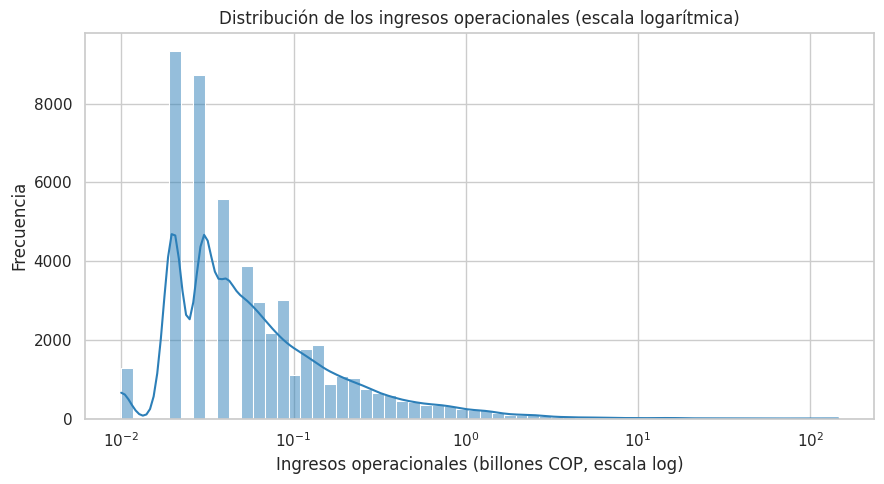

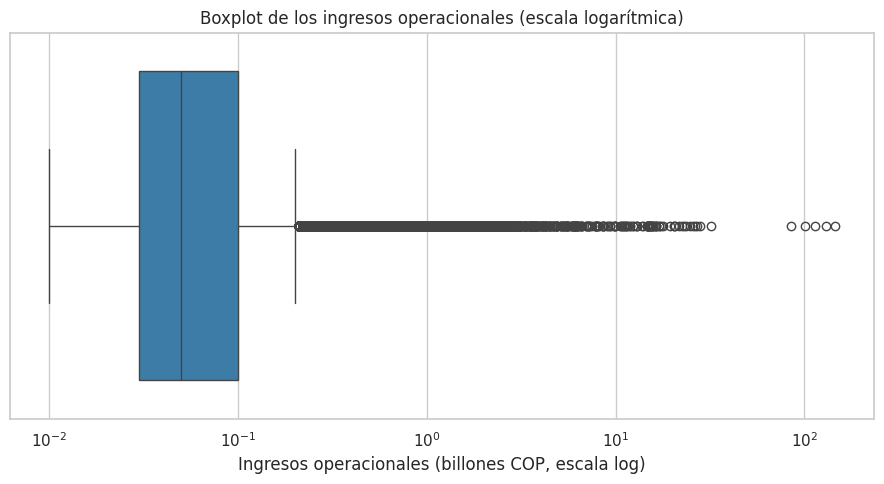

In [8]:
plt.figure()
sns.histplot(df["INGRESOS OPERACIONALES"], bins=60, kde=True, log_scale=True, color="#2c7fb8")
plt.title("Distribución de los ingresos operacionales (escala logarítmica)")
plt.xlabel(f"Ingresos operacionales ({UNIDAD}, escala log)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

plt.figure()
sns.boxplot(x=df["INGRESOS OPERACIONALES"], color="#2c7fb8")
plt.xscale("log")
plt.title("Boxplot de los ingresos operacionales (escala logarítmica)")
plt.xlabel(f"Ingresos operacionales ({UNIDAD}, escala log)")
plt.tight_layout()
plt.show()

### Forma de la distribución
En ingresos, el promedio es 0.17 y la mediana es 0.05. La asimetría es 68, muy alta. Esto significa que la distribución está muy sesgada hacia la derecha: la gran mayoría de las empresas tiene ingresos pequeños y muy pocas tienen ingresos gigantes que suben el promedio. Por eso, para hablar de una empresa "típica" uso la **mediana** y no el promedio. Las otras columnas de dinero tienen la misma forma (asimetrías entre 47 y 82), así que la misma decisión aplica a todas. Como los datos están tan estirados, los histogramas y boxplots usan escala logarítmica: sin ella solo se vería una barra pegada al borde.

### Outliers (valores atípicos)
Uso la regla del rango intercuartil: se considera atípico un ingreso mayor a Q3 + 1.5 × (Q3 − Q1). Los outliers **no los elimino**: son empresas reales muy grandes, y quitarlas borraría justo lo que este ranking quiere mostrar. Lo que hago es usar la mediana y la escala logarítmica para que no distorsionen la lectura.

In [9]:
q1 = df["INGRESOS OPERACIONALES"].quantile(0.25)
q3 = df["INGRESOS OPERACIONALES"].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)
outliers = df[df["INGRESOS OPERACIONALES"] > limite]

print(f"Límite superior: {limite:.3f}")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% de los registros)")
outliers.nlargest(5, "INGRESOS OPERACIONALES")[["RAZÓN SOCIAL", "Año de Corte", "INGRESOS OPERACIONALES"]]

Límite superior: 0.205
Outliers: 6361 (12.7% de los registros)


,RAZÓN SOCIAL,Año de Corte,INGRESOS OPERACIONALES
38914,ECOPETROL S.A.,2022,144.82
29531,ECOPETROL S.A.,2023,129.51
10026,ECOPETROL S.A.,2024,113.92
0,ECOPETROL S.A.,2025,100.59
41486,ECOPETROL S.A.,2021,84.95


Hay 6.361 registros atípicos (12,7%). Es normal en un ranking de empresas: incluso dentro de las 10.000 más grandes, unas pocas son enormes. Los 5 ingresos más altos son todos de Ecopetrol, uno por cada año, y son los que más estiran el promedio.

### Pregunta 1: ingresos por macrosector
Agrupo las empresas por macrosector y sumo sus ingresos. Ordeno de mayor a menor para ver de inmediato cuál sector concentra más ingresos.

In [10]:
ingresos_macrosector = df.groupby("MACROSECTOR")["INGRESOS OPERACIONALES"].sum().sort_values(ascending=False)
ingresos_macrosector

MACROSECTOR
COMERCIO        2680.41
SERVICIOS       2434.27
MANUFACTURA     1929.34
MINERO           982.03
CONSTRUCCIÓN     351.01
AGROPECUARIO     182.55
Name: INGRESOS OPERACIONALES, dtype: float64

Uso un gráfico de barras horizontales porque compara categorías (los macrosectores) y los nombres se leen mejor de lado. Está ordenado de mayor a menor para que la respuesta se vea sin esfuerzo.

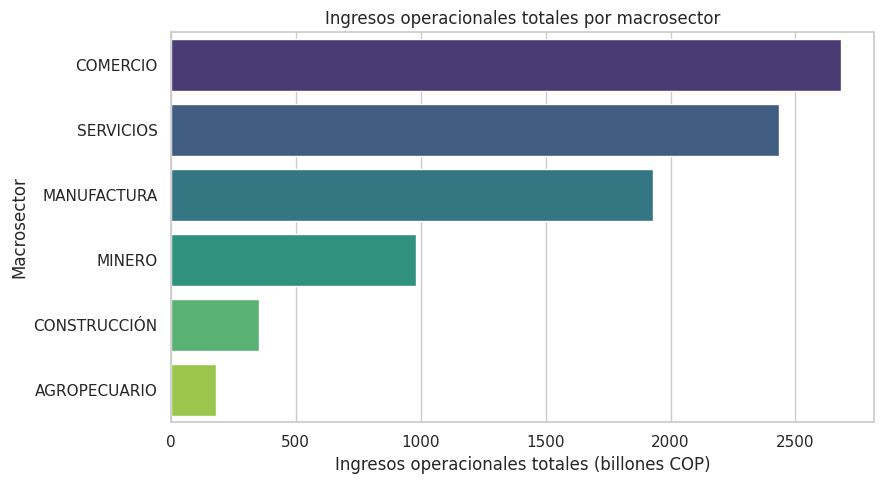

In [11]:
plt.figure()
sns.barplot(x=ingresos_macrosector.values, y=ingresos_macrosector.index, hue=ingresos_macrosector.index, palette="viridis", legend=False)
plt.title("Ingresos operacionales totales por macrosector")
plt.xlabel(f"Ingresos operacionales totales ({UNIDAD})")
plt.ylabel("Macrosector")
plt.tight_layout()
plt.show()

### Pregunta 2: ingresos por región
Hago lo mismo que con el macrosector, pero agrupando por región. Así comparo qué zona del país concentra más ingresos de las empresas grandes.

In [12]:
ingresos_region = df.groupby("REGIÓN")["INGRESOS OPERACIONALES"].sum().sort_values(ascending=False)
ingresos_region

REGIÓN
BOGOTÁ - CUNDINAMARCA    4959.94
ANTIOQUIA                1428.30
COSTA PACÍFICA            703.31
COSTA ATLÁNTICA           669.89
CENTRO - ORIENTE          272.63
EJE CAFETERO              198.74
REGIÓN CARIBE             195.67
OTROS                      94.27
CENTRO - SUR               24.50
LLANOS                     12.36
Name: INGRESOS OPERACIONALES, dtype: float64

Uso barras horizontales ordenadas, igual que en el gráfico anterior, para poder comparar las regiones de un vistazo.

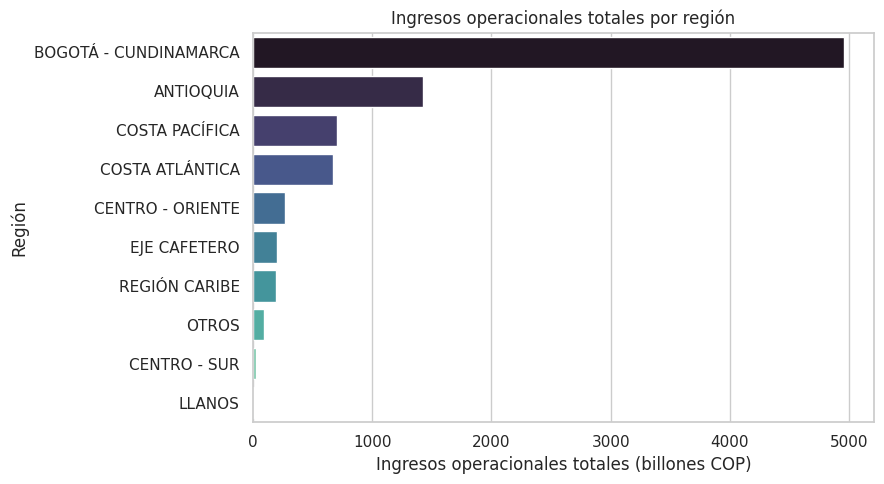

In [13]:
plt.figure()
sns.barplot(x=ingresos_region.values, y=ingresos_region.index, hue=ingresos_region.index, palette="mako", legend=False)
plt.title("Ingresos operacionales totales por región")
plt.xlabel(f"Ingresos operacionales totales ({UNIDAD})")
plt.ylabel("Región")
plt.tight_layout()
plt.show()

### Pregunta 3: cantidad de empresas por macrosector
Aquí no sumo dinero, solo cuento cuántos registros hay en cada macrosector. Como cada fila es una empresa en un año, el conteo incluye los 5 años (2021 a 2025).

In [14]:
empresas_macrosector = df["MACROSECTOR"].value_counts()
empresas_macrosector

MACROSECTOR
COMERCIO        17335
SERVICIOS       15689
MANUFACTURA     10033
CONSTRUCCIÓN     3854
AGROPECUARIO     2142
MINERO            947
Name: count, dtype: int64

Uso barras horizontales para comparar cuántas empresas tiene cada macrosector. Después comparo este gráfico con el de ingresos para ver si los sectores con más empresas son también los que más venden.

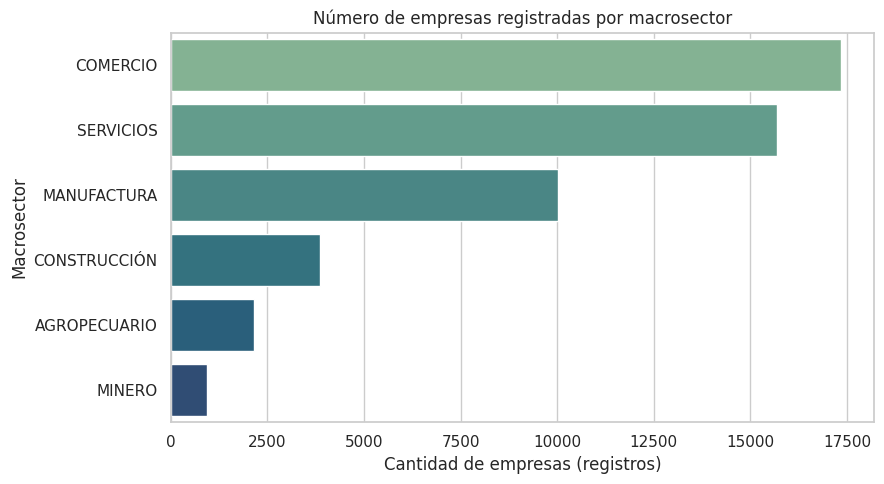

In [15]:
plt.figure()
sns.barplot(x=empresas_macrosector.values, y=empresas_macrosector.index, hue=empresas_macrosector.index, palette="crest", legend=False)
plt.title("Número de empresas registradas por macrosector")
plt.xlabel("Cantidad de empresas (registros)")
plt.ylabel("Macrosector")
plt.tight_layout()
plt.show()

### Comparación por grupo: total contra empresa típica
Agrupo por macrosector y calculo la cantidad de registros, el ingreso total y la **mediana** de ingresos. El total premia a los sectores con muchas empresas; la mediana muestra cuánto ingresa una empresa típica de cada sector.

In [16]:
df.groupby("MACROSECTOR")["INGRESOS OPERACIONALES"].agg(["count", "sum", "median"]).round(2).sort_values("sum", ascending=False)

,count,sum,median
MACROSECTOR,,,
COMERCIO,17335,2680.41,0.05
SERVICIOS,15689,2434.27,0.04
MANUFACTURA,10033,1929.34,0.05
MINERO,947,982.03,0.07
CONSTRUCCIÓN,3854,351.01,0.04
AGROPECUARIO,2142,182.55,0.04


Comercio suma más ingresos porque tiene muchísimas empresas, pero la empresa típica de **Minero** es la que más ingresa (mediana 0.07 contra 0.05 en Comercio y Manufactura). Es decir, el peso de Comercio viene de la cantidad y no de que sus empresas sean individualmente más grandes.

### Pregunta 4: relación entre activos, ingresos y patrimonio
La correlación es un número entre -1 y 1 que dice qué tan juntas se mueven dos variables. Cerca de 1 significa que cuando una sube, la otra también. Cerca de 0 significa que no tienen relación. Uso un heatmap (mapa de calor) porque muestra todas las combinaciones en una sola imagen con colores.

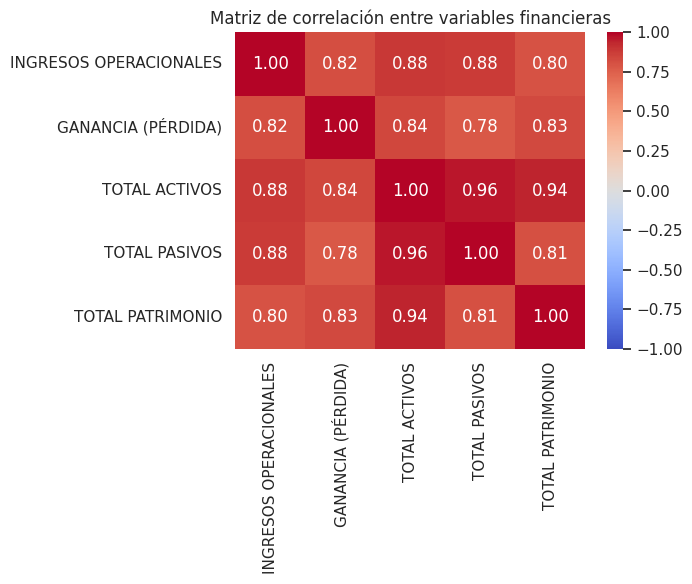

In [17]:
num_cols = ["INGRESOS OPERACIONALES", "GANANCIA (PÉRDIDA)", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación entre variables financieras")
plt.tight_layout()
plt.show()

Todas las variables de dinero se correlacionan de forma positiva y fuerte: los valores van de 0.78 a 0.96. Los pares más fuertes son activos con pasivos (0.96) y activos con patrimonio (0.94). Esto es en parte contable: los activos son igual a pasivos más patrimonio, así que se mueven juntos por definición. La relación de activos con ingresos (0.88) es la que aporta información nueva: las empresas con más activos también venden más.

### Scatter de los pares más correlacionados
Un punto por empresa. Uso escala logarítmica en ambos ejes para que se vean juntas las empresas pequeñas y las gigantes.

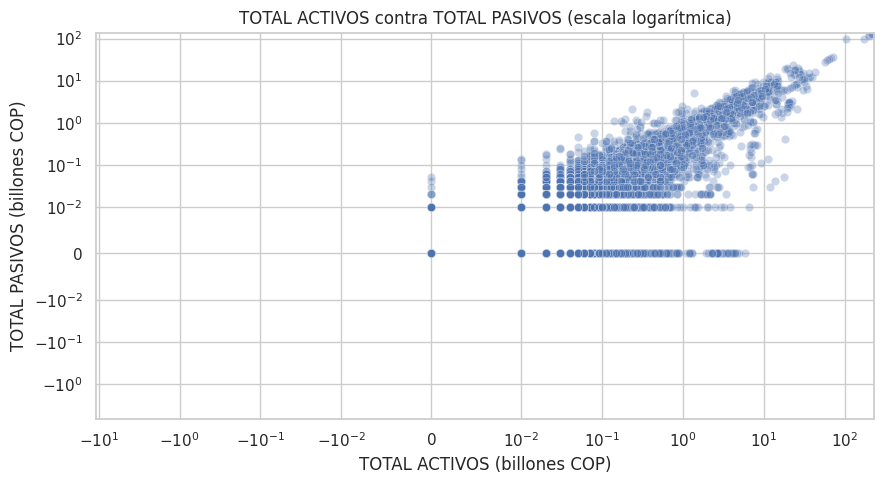

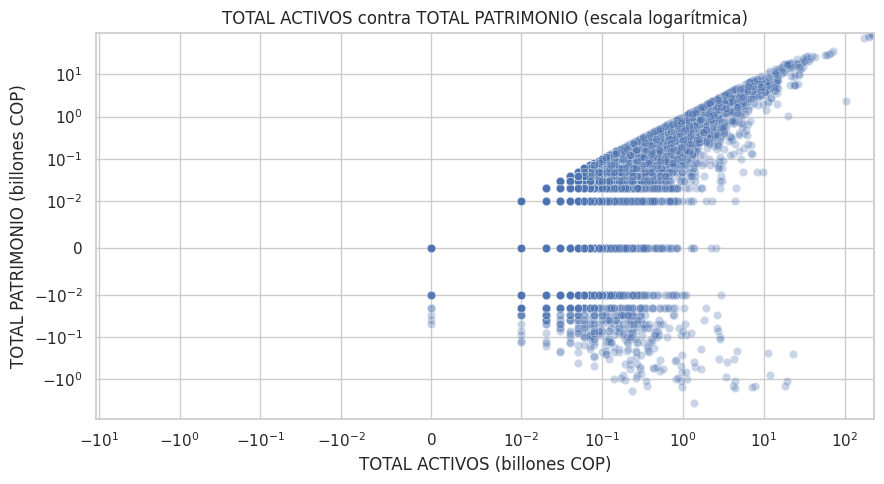

In [18]:
pares = [("TOTAL ACTIVOS", "TOTAL PASIVOS"), ("TOTAL ACTIVOS", "TOTAL PATRIMONIO")]

for x, y in pares:
    plt.figure()
    sns.scatterplot(data=df, x=x, y=y, alpha=0.3)
    plt.xscale("symlog", linthresh=0.01)
    plt.yscale("symlog", linthresh=0.01)
    plt.title(f"{x} contra {y} (escala logarítmica)")
    plt.xlabel(f"{x} ({UNIDAD})")
    plt.ylabel(f"{y} ({UNIDAD})")
    plt.tight_layout()
    plt.show()

Los puntos siguen una franja casi recta que sube: a más activos, más pasivos y más patrimonio. Hay algunos puntos con patrimonio negativo (empresas cuyas deudas superan lo que tienen).

### Activos contra ingresos
Este par responde directamente la pregunta 4: si tener más activos se asocia con vender más. Coloreo por macrosector para ver si algún sector se comporta distinto.

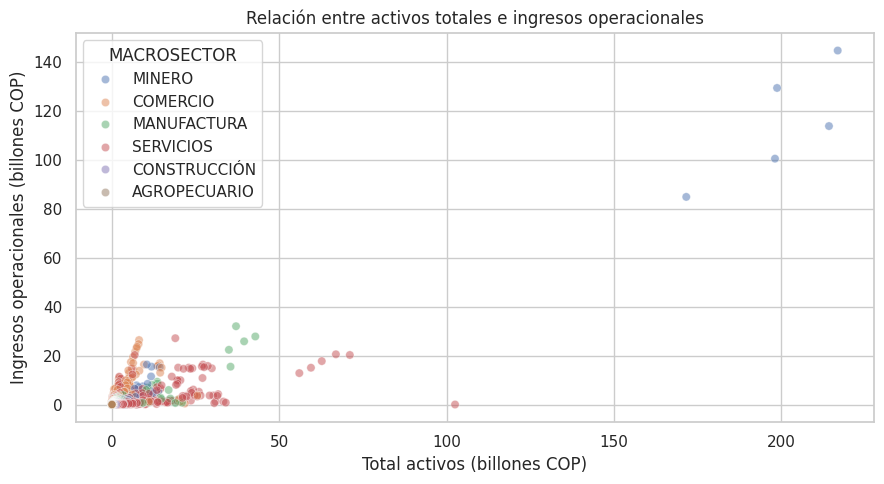

In [19]:
plt.figure()
sns.scatterplot(data=df, x="TOTAL ACTIVOS", y="INGRESOS OPERACIONALES", hue="MACROSECTOR", alpha=0.5)
plt.title("Relación entre activos totales e ingresos operacionales")
plt.xlabel(f"Total activos ({UNIDAD})")
plt.ylabel(f"Ingresos operacionales ({UNIDAD})")
plt.tight_layout()
plt.show()

## Respuesta a las preguntas de investigación

**1. ¿Qué macrosector económico concentra mayores ingresos operacionales?**
El macrosector COMERCIO tiene el mayor ingreso operacional acumulado (2021-2025), seguido de cerca por SERVICIOS y luego por MANUFACTURA. MINERO, CONSTRUCCIÓN y AGROPECUARIO quedan muy por debajo, aunque MINERO incluye a la empresa más grande del país (Ecopetrol). Un dato que matiza esto: la empresa típica (mediana) de MINERO es la que más ingresa, así que el liderazgo de Comercio viene de su cantidad de empresas y no de que sean más grandes cada una.

**2. ¿Qué región concentra los mayores ingresos operacionales?**
BOGOTÁ - CUNDINAMARCA concentra, con mucho margen, los mayores ingresos de las empresas más grandes del país: casi 3,5 veces los de ANTIOQUIA, que es la segunda. Le siguen la COSTA PACÍFICA y la COSTA ATLÁNTICA, con valores mucho menores. Probablemente influye que muchas empresas registran su domicilio en la capital, pero con estos datos no podemos comprobarlo. Para una entidad de fomento regional, esto muestra que la actividad de las grandes empresas está muy concentrada, y que regiones como LLANOS o CENTRO - SUR casi no aparecen en el ranking.

**3. ¿Qué macrosectores concentran el mayor número de empresas?**
COMERCIO y SERVICIOS, que juntos son más de la mitad de todos los registros del listado (cerca de dos tercios), seguidos por MANUFACTURA. Esto coincide con que también son los sectores que más ingresos suman (pregunta 1), pero por la cantidad y no por el tamaño individual de las empresas.

**4. ¿Las empresas con más activos también tienen más ingresos operacionales y más patrimonio?**
Sí, hay una relación fuerte y positiva: la correlación de activos con ingresos es 0.88 y con patrimonio es 0.94 (1 sería una relación perfecta). En general, las empresas con más activos también venden más y tienen más patrimonio. La relación con el patrimonio es en parte contable, porque los activos son pasivos más patrimonio. Además, unas pocas empresas gigantes (Ecopetrol, entre otras) pesan mucho en el cálculo.

## Limitaciones
- El dataset solo incluye las 10.000 empresas más grandes de cada año, así que no permite concluir nada sobre empresas pequeñas ni sobre la economía completa.
- La región es el lugar del domicilio registrado, no necesariamente donde la empresa opera.
- Cada fila es una empresa en un año: una misma empresa se cuenta hasta 5 veces, por lo que los conteos son de registros y no de empresas distintas.
- Los ingresos de las preguntas 1 y 2 suman 5 años, por lo que no muestran cómo cambió cada año.
- La correlación mide si dos variables se mueven juntas, no que una cause la otra.